# Devoir 1 - Modélisation, optimisation et séparation de groupes

*Imane Atif et Chaimae El Yaouti*
*data science*


## Application au crédit bancaire

Dans ce notebook, nous analysons la base de données fournie afin de comprendre les variables explicatives et la variable de classe `charged_off`, puis nous illustrons le problème de classification dans le contexte du crédit bancaire.

# Exercice 1 : Modélisation générale

## 1. Écriture des contraintes

On cherche à séparer deux groupes $G_1$ et $G_2$ à l’aide d’un hyperplan :

$$
a^T x = k
$$

Les conditions idéales de séparation sont :

- pour $i \in G_1$ :
$$
a^T x_i \ge k
$$

- pour $i \in G_2$ :
$$
a^T x_i \le k
$$

## 2. Introduction des variables d’écart

Pour chaque observation $i$, on introduit :

- $E_i$ : écart externe, qui mesure une mauvaise classification ;
- $I_i$ : écart interne, qui mesure la distance d’un point correctement classé à la frontière.

## 3. Modèle complet

Le modèle s’écrit différemment selon le groupe :

- pour $i \in G_1$ :
$$
a^T x_i + E_i - I_i = k
$$

- pour $i \in G_2$ :
$$
a^T x_i - E_i + I_i = k
$$

avec :

$$
E_i \ge 0, \qquad I_i \ge 0
$$

Les écarts externes sont indésirables car ils traduisent des erreurs de classement, tandis que les écarts internes sont désirables car ils traduisent une bonne séparation.

# Exercice 2 : Forme matricielle

## 1. Contraintes sous forme matricielle

En notant $A_1$ la matrice des observations du groupe $G_1$ et $A_2$ celle du groupe $G_2$, on peut écrire :

$$
A_1X + E_1 - I_1 = k\mathbf{1}
$$

$$
A_2X - E_2 + I_2 = k\mathbf{1}
$$

On peut aussi proposer une forme compacte du type :

$$
AX + E - I = k\mathbf{1}
$$

en précisant que les signes dépendent du groupe considéré.

## 2. Définition des vecteurs

- $E = (E_i)_{i=1,\dots,n}$ : vecteur des écarts externes
- $I = (I_i)_{i=1,\dots,n}$ : vecteur des écarts internes

## 3. Interprétation

- $X$ est le vecteur des coefficients de séparation ;
- $\mathbf{1}$ est le vecteur unité de dimension $n$.

## 4. Dimensions

- $A \in \mathbb{R}^{n \times p}$
- $X \in \mathbb{R}^{p \times 1}$
- $E,I \in \mathbb{R}^{n \times 1}$
- $k\mathbf{1} \in \mathbb{R}^{n \times 1}$

# Exercice 3 : Fonction objectif

## 1. Fonction objectif

La fonction objectif est :

$$
\min \left(
\sum_{i \in G_1} h_1 E_i
+
\sum_{i \in G_2} h_2 E_i
-
\sum_{i \in G_1} m_1 I_i
-
\sum_{i \in G_2} m_2 I_i
\right)
$$

## 2. Interprétation des termes

- Les termes en $E_i$ pénalisent les erreurs de classification.
- Les termes en $I_i$ récompensent les bonnes classifications éloignées de la frontière.

## 3. Pourquoi distingue-t-on $G_1$ et $G_2$ ?

La distinction entre les deux groupes permet d’introduire des coûts d’erreur différents selon le groupe.  
Dans une application bancaire, classer un mauvais client comme bon peut coûter plus cher que l’erreur inverse.

## 4. Effet des coefficients $h_i$ et $m_i$

- un coefficient $h_i$ élevé augmente la pénalisation des erreurs ;
- un coefficient $m_i$ élevé favorise une plus grande marge interne.

## 5. Justification de la condition

$$
h_1 \ge m_1, \qquad h_2 \ge m_2
$$

Cette condition signifie que le coût d’une erreur doit rester au moins aussi important que le bénéfice d’une bonne classification.

# Exercice 4 : Analyse théorique

## 1. Pourquoi le problème peut être non borné ?

Sans contrainte de normalisation, si $(X,k)$ est une solution, alors pour tout $c>1$, $(cX,ck)$ peut produire une solution de même nature mais avec une valeur d’objectif qui évolue sans contrôle.  
Le problème peut donc devenir non borné.

## 2. Contrainte de normalisation

Une contrainte classique est :

$$
q_j X + k = 1
$$

où $q_j$ est un vecteur de 1.  
Cela revient à écrire :

$$
\sum_{j=1}^{p} X_j + k = 1
$$

## 3. Rôle de la normalisation

Cette contrainte permet de :

- fixer l’échelle des coefficients ;
- éviter les solutions triviales ;
- rendre le problème bien posé.

## 4. Existence et unicité

L’existence d’une solution est généralement assurée grâce aux variables d’écart $E_i$ et $I_i$.  
En revanche, l’unicité n’est pas garantie, car plusieurs hyperplans peuvent conduire à la même valeur optimale.

# Exercice 5 : Étude qualitative

## 1. Que deviennent les variables $E_i$ ?

Si les données ne sont pas linéairement séparables, alors certaines variables $E_i$ deviennent strictement positives :

$$
E_i > 0
$$

Cela signifie que certaines observations sont mal classées ou difficiles à séparer.

## 2. Le problème admet-il toujours une solution ?

Oui, car les variables d’écart permettent au modèle de s’adapter même lorsque les deux groupes se chevauchent.

## 3. Quel compromis est réalisé ?

Le modèle cherche un compromis entre :

$$
\text{minimiser les erreurs } E_i
\quad \text{et} \quad
\text{maximiser les marges internes } I_i
$$

## 4. Interprétation en classification

Le modèle fournit une règle de classification.  
Un client ayant un $I_i$ élevé est bien classé et éloigné de la frontière de décision.  
À l’inverse, un client pour lequel $E_i>0$ correspond à un profil difficile à classer ou mal représenté par les variables explicatives.

# Exercice 6 : Multiplicateurs du simplexe

## Partie A : Compréhension théorique

### 1. Définition

Le multiplicateur du simplexe, noté $\lambda_i$, est une variable duale associée à une contrainte du modèle d’optimisation.

Il mesure la variation de la fonction objectif lorsque l’on modifie légèrement la contrainte associée à l’observation $i$.

---

### 2. Association

Chaque multiplicateur $\lambda_i$ est associé à une contrainte correspondant à une observation (un client).

Ainsi, chaque client du dataset possède un multiplicateur.

---

### 3. Interprétation des valeurs

- Si :

$$
\lambda_i = 0
$$

Alors la contrainte est **non active**.  
Le point est loin de la frontière de décision et n’influence pas la solution.

---

- Si :

$$
\lambda_i > 0
$$

Alors la contrainte est **active (saturée)**.  
Le point est situé sur la frontière de décision et influence directement l’hyperplan.

---

### 4. Conclusion théorique

Les observations avec $\lambda_i > 0$ sont les plus importantes pour le modèle, car elles déterminent la position de la frontière de séparation.

In [2]:
import pandas as pd
from pulp import *

# 1. Charger les données
df = pd.read_excel("p2pdata.xlsx")

# Nettoyage
df = df.dropna()

if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# Variables
features = ['loan_amnt', 'emp_length', 'purpose', 'addr_state', 'dti', 'fico_score']

n = len(df)
p = len(features)

# 2. Définition du problème
prob = LpProblem("Credit_Scoring_Optimization", LpMinimize)

# 3. Variables
a = [LpVariable(f"a_{j}", lowBound=None) for j in range(p)]
k = LpVariable("k", lowBound=None)

E = [LpVariable(f"E_{i}", lowBound=0) for i in range(n)]
I = [LpVariable(f"I_{i}", lowBound=0) for i in range(n)]

# 4. Fonction objectif
prob += lpSum([E[i] - 0.1 * I[i] for i in range(n)])

# 5. Contraintes
constraints = []

for i in range(n):
    score = lpSum([a[j] * df.iloc[i][features[j]] for j in range(p)])

    if df.iloc[i]['charged_off'] == 0:
        c = (score + E[i] - I[i] == k)
    else:
        c = (score - E[i] + I[i] == k)

    prob += c
    constraints.append(c)

# Contrainte de normalisation
prob += lpSum(a) == 1

# 6. Résolution
prob.solve()

# 7. Récupération des multiplicateurs
df_results = df.copy()
df_results["lambda"] = [c.pi for c in constraints]

# Affichage des clients critiques
df_results.sort_values(by="lambda", ascending=False)[
    ["fico_score", "dti", "loan_amnt", "lambda"]
].head(10)

,fico_score,dti,loan_amnt,lambda
481917,662.0,23.58,24000.0,1.0
487763,662.0,20.57,5000.0,1.0
481890,697.0,13.26,20000.0,1.0
487791,667.0,25.70,15000.0,1.0
487788,702.0,15.50,28000.0,1.0
485982,692.0,16.70,12000.0,1.0
485985,687.0,29.97,18125.0,1.0
489701,692.0,24.89,17600.0,1.0
129034,662.0,25.38,20000.0,1.0
129035,692.0,27.37,31500.0,1.0


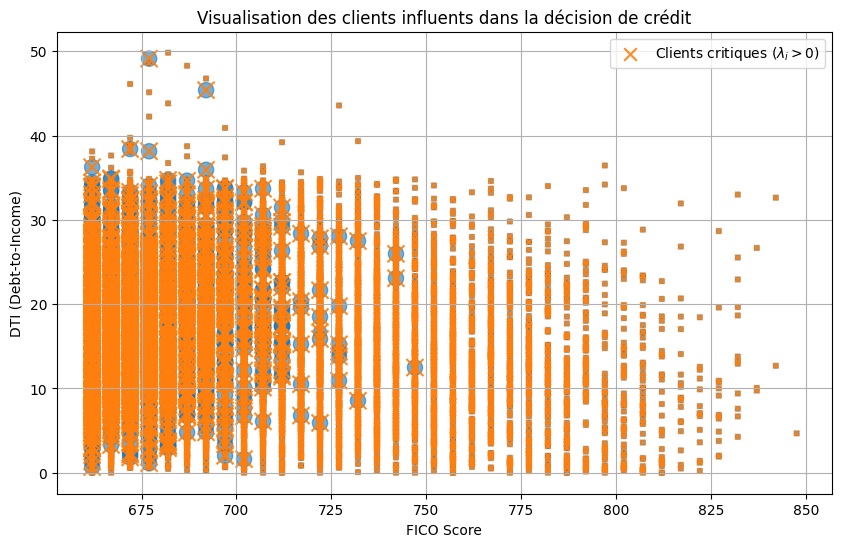

In [4]:
import matplotlib.pyplot as plt

# Figure
plt.figure(figsize=(10, 6))

# Nuage de points
plt.scatter(
    df_results["fico_score"],
    df_results["dti"],
    s=df_results["lambda"] * 120,   # taille selon lambda
    alpha=0.6
)

# Mettre en évidence les points critiques
critical_points = df_results[df_results["lambda"] > 0]

plt.scatter(
    critical_points["fico_score"],
    critical_points["dti"],
    s=critical_points["lambda"] * 150,
    alpha=0.9,
    marker="x",
    label="Clients critiques ($\\lambda_i > 0$)"
)

# Habillage
plt.xlabel("FICO Score")
plt.ylabel("DTI (Debt-to-Income)")
plt.title("Visualisation des clients influents dans la décision de crédit")
plt.legend()
plt.grid(True)
plt.show()

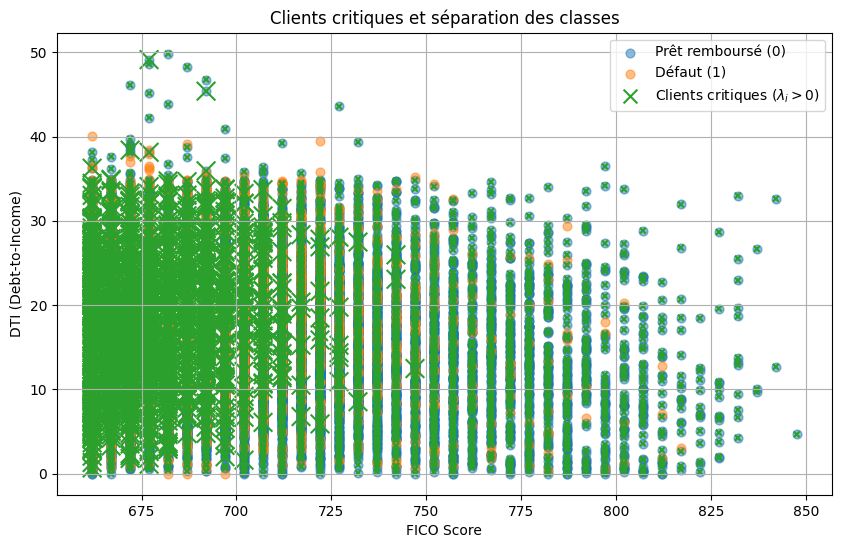

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Classe 0
group0 = df_results[df_results["charged_off"] == 0]
plt.scatter(
    group0["fico_score"],
    group0["dti"],
    s=40,
    alpha=0.5,
    label="Prêt remboursé (0)"
)

# Classe 1
group1 = df_results[df_results["charged_off"] == 1]
plt.scatter(
    group1["fico_score"],
    group1["dti"],
    s=40,
    alpha=0.5,
    label="Défaut (1)"
)

# Clients critiques
critical_points = df_results[df_results["lambda"] > 0]
plt.scatter(
    critical_points["fico_score"],
    critical_points["dti"],
    s=critical_points["lambda"] * 180,
    alpha=1,
    marker="x",
    label="Clients critiques ($\\lambda_i > 0$)"
)

plt.xlabel("FICO Score")
plt.ylabel("DTI (Debt-to-Income)")
plt.title("Clients critiques et séparation des classes")
plt.legend()
plt.grid(True)
plt.show()


Le graphique représente les clients selon leur score de crédit (FICO) et leur ratio dette/revenu (DTI), en distinguant les deux classes : prêts remboursés (0) et défauts (1).

On observe que les deux groupes sont fortement mélangés, ce qui indique qu’il n’existe pas une séparation nette entre les bons et les mauvais clients uniquement à partir de ces deux variables.

Les clients ayant un multiplicateur strictement positif sont marqués par des croix.  
Ils sont principalement situés dans les zones où les deux classes se chevauchent.

Cela montre que ces observations se trouvent dans des régions où la distinction entre les clients est difficile, et qu’elles jouent un rôle important dans la détermination de la frontière de décision.

# Interprétation *

L’analyse réalisée permet de construire un modèle de séparation entre deux groupes de clients :

- les clients fiables (prêt remboursé) ;
- les clients en défaut de paiement.

---

## 1. Difficulté de séparation

Les graphiques montrent que les deux classes sont fortement imbriquées dans l’espace des variables, notamment selon le score de crédit (FICO) et le ratio dette/revenu (DTI).

Cela signifie qu’il n’existe pas de séparation parfaite entre les deux groupes, ce qui justifie l’introduction des variables d’écart dans le modèle.

---

## 2. Rôle des variables explicatives

Les variables utilisées permettent de caractériser le profil financier des clients :

- le score FICO reflète la fiabilité financière ;
- le ratio DTI mesure le niveau d’endettement ;
- le montant du prêt influence le risque global.

Ces variables contribuent à la construction de la frontière de décision.

---

## 3. Rôle des variables d’écart

Les variables $E_i$ et $I_i$ jouent un rôle essentiel :

- $E_i > 0$ indique une mauvaise classification ou une difficulté à séparer un client ;
- $I_i$ mesure la distance d’un client correctement classé à la frontière.

Le modèle réalise un compromis entre minimisation des erreurs et maximisation de la marge.

---

## 4. Rôle des multiplicateurs du simplexe

Les multiplicateurs $\lambda_i$ permettent d’identifier les observations les plus influentes.

Les clients ayant $\lambda_i > 0$ sont situés dans des zones où les deux classes se chevauchent.

Ils jouent un rôle clé dans la détermination de la frontière de séparation.

---

## 5. Interprétation métier

Du point de vue de la banque :

- les clients facilement classés correspondent à des profils clairement bons ou mauvais ;
- les clients proches de la frontière représentent des cas ambigus ;
- ces derniers nécessitent une analyse plus approfondie.

Le modèle permet donc d’identifier les profils à risque intermédiaire et d’améliorer la prise de décision.

---

## Conclusion

Le modèle de séparation permet de distinguer les clients selon leur risque de défaut, malgré l’absence de séparation parfaite dans les données.

Il fournit un outil d’aide à la décision en identifiant les observations les plus critiques et en mettant en évidence les facteurs influençant le risque de crédit.